In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel('merged_data.xlsx')
df["Donor"] = df["Donor"].astype("string").str.strip()
df["Treg"] = pd.to_numeric(df["Treg"].astype(
    "string").str.strip(), errors="coerce")

In [5]:
# from src.pipeline import summarize_categorical_data, plot_categorical_summary

# categorical_summary = summarize_categorical_data(df)
# plot_categorical_summary(categorical_summary, variables=[
#                          "Sex", "Ethnicity", "Tissue"])

In [3]:
from src.pipeline import analyze_tissue_demographics

df = df.rename(columns={
    "Ethnicity:": "Ethnicity",
    "Age (yr):": "Age",
    "BMI (kg/m^2):": "BMI",
    "Sex:": "Sex",
})

exclude_cols = {"Donor", "Ethnicity", "Age", "BMI", "Sex", "Tissue"}
subsets_to_test = [col for col in df.columns if col not in exclude_cols]

summary_stats_df = analyze_tissue_demographics(
    df, subset_columns=subsets_to_test
)

2026-11-10 16:49:41,044 - INFO - Processing Target Subset: CD4 CD45RA+CCR7+
2026-11-10 16:49:41,057 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue SPL: [(1532, 'Alaska Native')]
2026-11-10 16:49:41,063 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue TONS: [(3, 'Asian')]
2026-11-10 16:49:41,064 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue LLN: [(1536, 'Alaska Native')]
2026-11-10 16:49:41,071 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue MLN: [(1535, 'Alaska Native')]
2026-11-10 16:49:41,077 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue ILN: [(6, 'Asian')]
2026-11-10 16:49:41,083 - WARNING - Excluding singleton non-reference ethnicity observation(s) for CD4 CD45RA+CCR7+ in tissue SG: [(7, 'Asian')]
2026-11-10 16:4

In [4]:
summary_stats_df

,Subset,Tissue,N_Samples,Demographic_Variable,Coefficient,Std_Err,p_value,CI_Lower,CI_Upper,Is_Significant,p_value_FDR,Is_Significant_FDR
0,CD4 CD45RA+CCR7+,BLD,136,Sex: FEMALE,-0.204284,4.026419,0.959536,-8.095920,7.687352,False,0.992906,False
1,CD4 CD45RA+CCR7+,BLD,136,Ethnicity: Asian,-12.928430,12.107708,0.285617,-36.659102,10.802241,False,0.788423,False
2,CD4 CD45RA+CCR7+,BLD,136,Ethnicity: Black or African American,-8.253262,4.856505,0.089239,-17.771838,1.265313,False,0.549963,False
3,CD4 CD45RA+CCR7+,BLD,136,Ethnicity: Hispanic/Latino,-9.489516,4.677559,0.042486,-18.657364,-0.321669,True,0.416876,False
4,CD4 CD45RA+CCR7+,BLD,136,Age,-0.353556,0.102508,0.000563,-0.554467,-0.152644,True,0.022586,True
...,...,...,...,...,...,...,...,...,...,...,...,...
1320,CD8 CD69+,SPL,21,Sex: FEMALE,-9.436872,9.677393,0.329488,-28.404213,9.530469,False,0.825277,False
1321,CD8 CD69+,SPL,21,Ethnicity: Black or African American,-8.372489,11.572608,0.469388,-31.054384,14.309406,False,0.900057,False
1322,CD8 CD69+,SPL,21,Ethnicity: Hispanic/Latino,12.659501,13.418128,0.345444,-13.639546,38.958548,False,0.838447,False
1323,CD8 CD69+,SPL,21,Age,0.234437,0.183529,0.201467,-0.125273,0.594147,False,0.705828,False


In [5]:
significant_hits = summary_stats_df[summary_stats_df["Is_Significant_FDR"]]
significant_hits = significant_hits[~significant_hits["Demographic_Variable"].isin([
                                                                                   "Age", "BMI"])]
significant_hits[["Subset", "Tissue",
                  "Demographic_Variable", "Coefficient", "p_value", "p_value_FDR"]]

,Subset,Tissue,Demographic_Variable,Coefficient,p_value,p_value_FDR
37,CD4 CD45RA+CCR7+,LNG,Ethnicity: Black or African American,-10.399033,0.000118,0.006515
206,CD4 CD45RA+CCR7-,HLN,Sex: FEMALE,7.306294,0.000799,0.031152
1282,CD8 CD103+CD69+,SPL,Ethnicity: Hispanic/Latino,14.260375,0.001271,0.041073


In [ ]:
# from src.pipeline import regression_bmi

# regression_bmi(df, subset='Treg', tissue='SPL')

2026-11-10 16:49:45,955 - INFO - Excluding ethnicity groups with fewer than 2 observations for CD4 CD45RA+CCR7+ in tissue LNG: ['Alaska Native', 'American Indian']
2026-11-10 16:49:45,960 - INFO - Outlier donors for CD4 CD45RA+CCR7+ in tissue LNG: D0118, D0015, D0028, D0107, HDL040, HDL042, HDL047, HDL049, HDL050, HDL073, HDL078, HDL082, HDL085, HDL092, HDL097, HDL124, HDL134


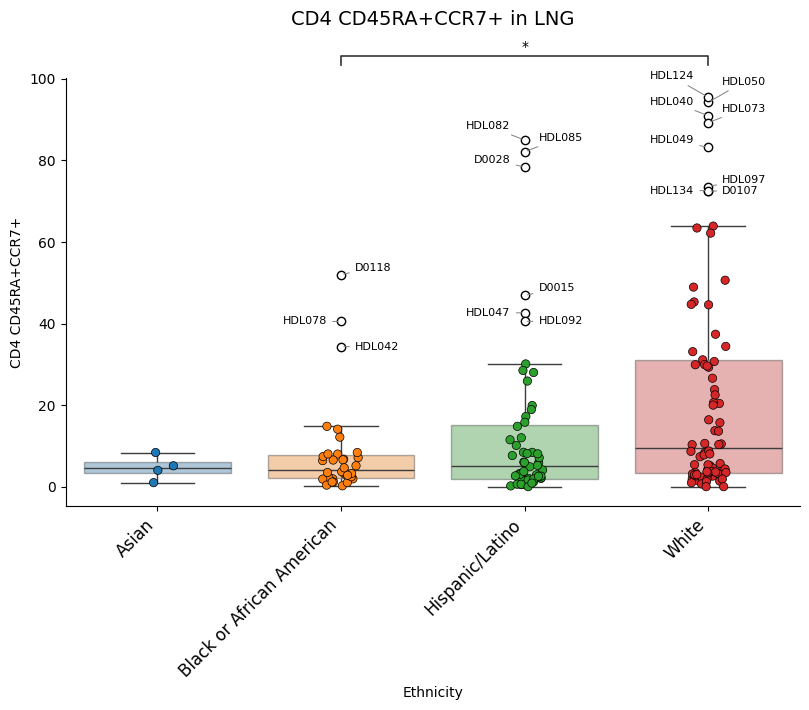

In [6]:
from src.pipeline import stat_boxplot
stat_boxplot(df, population_name='CD4 CD45RA+CCR7+', tissue='LNG')

In [ ]:
# from src.pipeline import sex_boxplot
# sex_boxplot(df, population_name='Treg', tissue='ILE')

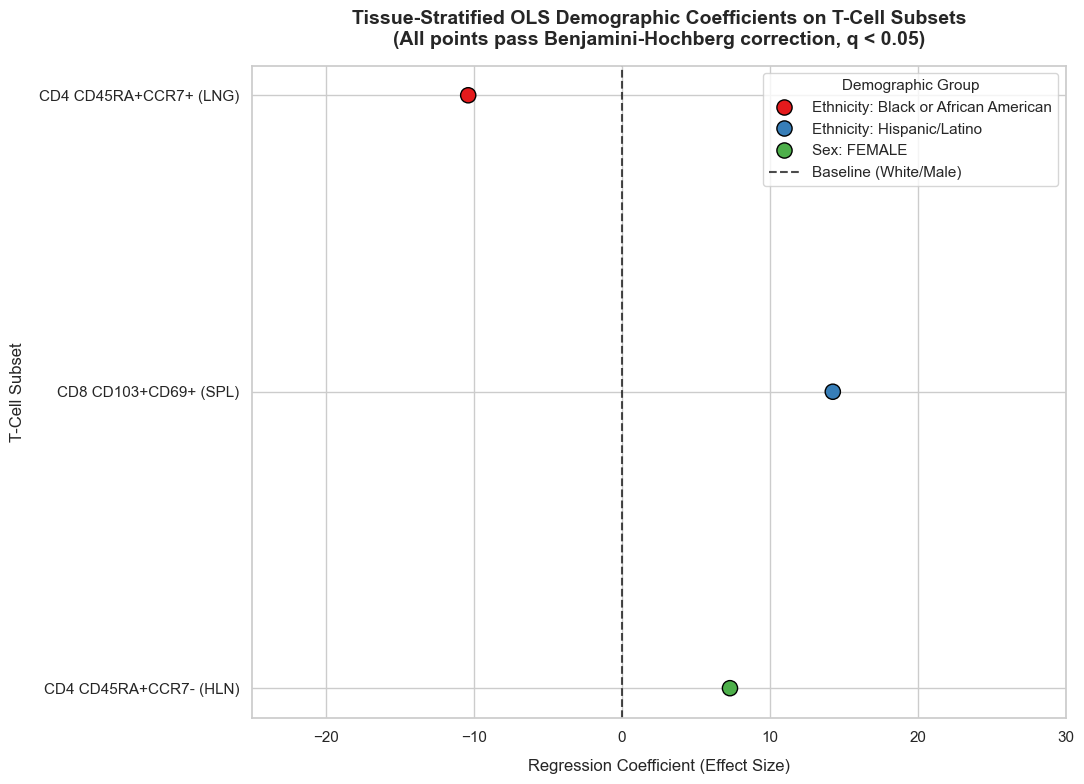

In [6]:
from src.pipeline import ols_summary
ols_summary(significant_hits)

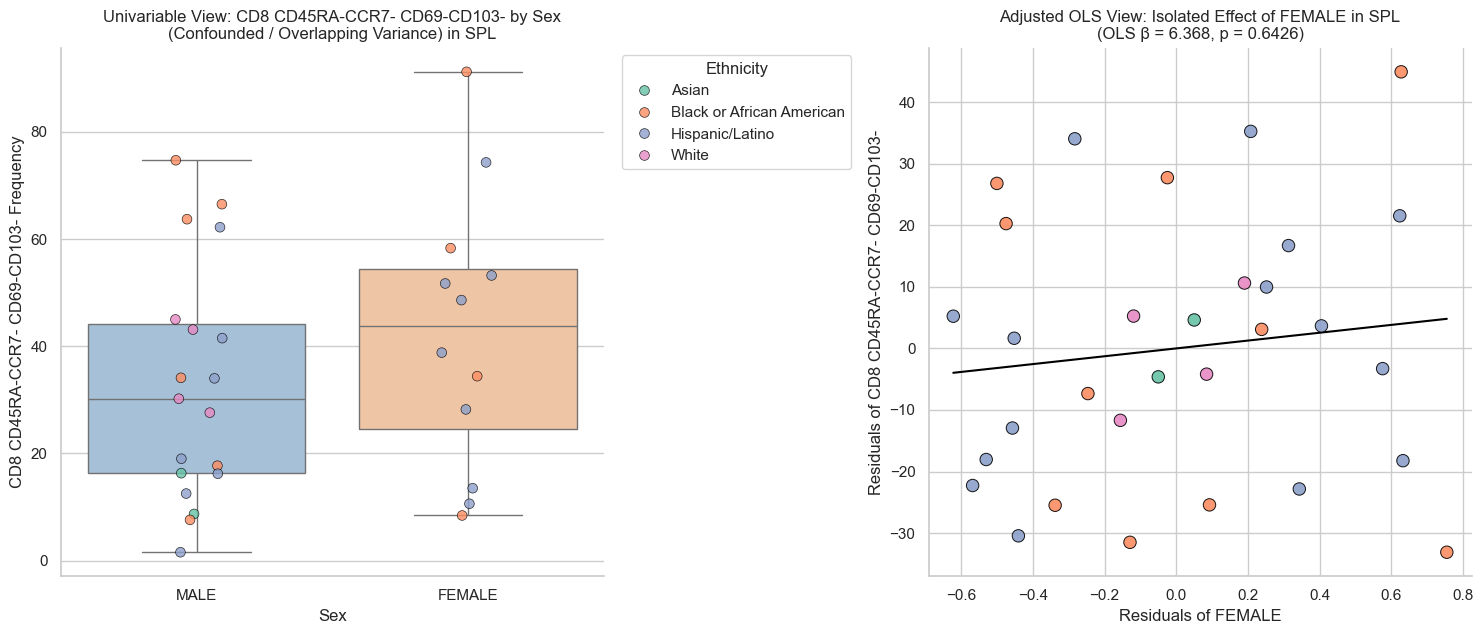

In [10]:
from src.pipeline import visualize_ols_vs_mann_whitney_colored
visualize_ols_vs_mann_whitney_colored(
    df=df,
    population_name="CD8 CD45RA-CCR7- CD69-CD103-",
    tissue="SPL",
    target_variable="C(Sex, Treatment(reference='MALE'))[T.FEMALE]",
    color_by="Ethnicity"
)

/Users/derekmartinez/Documents/Farber Lab/Donor Integrative Study/Donor Integrative Analysis/src/pipeline.py:772: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([


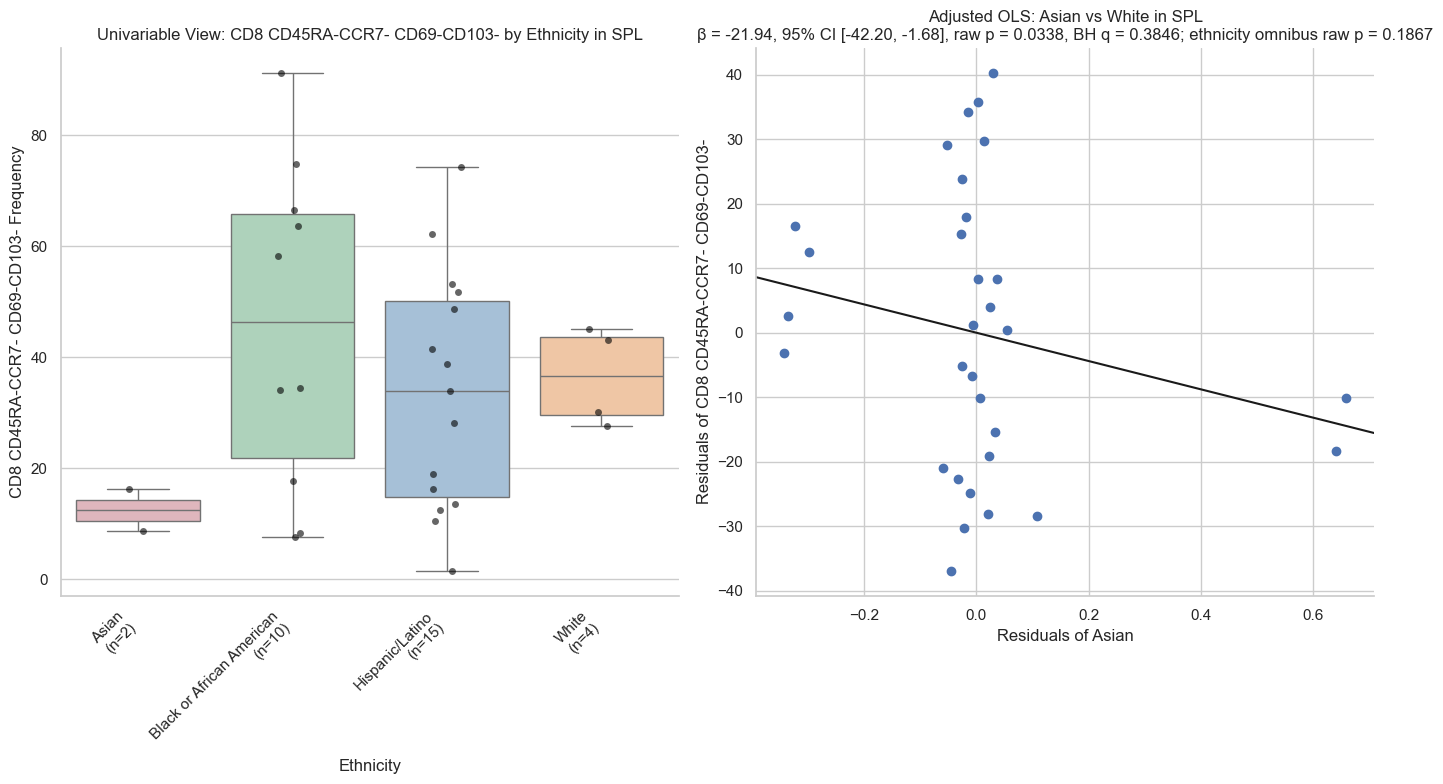

In [7]:
from src.pipeline import visualize_ols_vs_mann_whitney
target_variable = "C(Ethnicity, Treatment(reference='White'))[T.Asian]"
target_q = summary_stats_df.loc[
    (summary_stats_df["Subset"] == "CD8 CD45RA-CCR7- CD69-CD103-") &
    (summary_stats_df["Tissue"] == "SPL") &
    (summary_stats_df["Demographic_Variable"] == "Ethnicity: Asian"),
    "p_value_FDR"
]
visualize_ols_vs_mann_whitney(
    df=df,
    population_name="CD8 CD45RA-CCR7- CD69-CD103-",
    tissue="SPL",
    target_variable=target_variable,
    adjusted_p_value=target_q.iloc[0] if not target_q.empty else None,
)